# GreenTravel Intelligence Challenge — Part B
## High-Carbon Trip Prediction: EDA, Feature Engineering & Modeling

This notebook builds a binary classifier to predict `HighCarbon` for the private
(test) trip set, using only information that would be known **before** a trip is
booked. It covers:

1. Load data
2. Exploratory data analysis
3. Event-log feature engineering (booking lead time, cycle times, exception counts)
4. Trip + attribute feature engineering
5. Cross-validated XGBoost model
6. Feature importance
7. Final model + `submission.csv`

**Banned features** (would leak the answer, per the challenge rules): `Departure_CO2e`,
`Return_CO2e`, `Hotel_CO2e`, `Spend_CO2e`, `TotalCO2e`, `HighCarbon` itself — these are
dropped immediately after load and never used.

> **Data note:** an earlier pass of this notebook was missing `public_trip_event_log.csv`
> (only the private version was available), so event-log timing features couldn't be
> used — a feature must be buildable identically on both train and test. That file has
> since been recovered, so this version uses **all six data files** and adds real
> process-timing features (booking lead time, approval/expense cycle time, exception
> counts) alongside the trip and event-attributes data.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix, RocCurveDisplay
import xgboost as xgb

pd.set_option('display.max_columns', 50)
plt.rcParams['figure.figsize'] = (8, 4.5)

DATA_DIR = 'project'  # folder containing the CSVs
BANNED = ['Departure_CO2e', 'Return_CO2e', 'Hotel_CO2e', 'Spend_CO2e', 'TotalCO2e', 'HighCarbon']
HAPPY_PATH = {'Book Mode of Transportation', 'Book Lodging', 'Submit Travel Request', 'Travel Request Approved',
              'Receive Confirmation', 'Take Departure Flight', 'Take Return Flight', 'Take Departure Train',
              'Take Return Train', 'Submit Expense Request', 'Expense Request Approved', 'Expense Reimbursement',
              'Pickup Rental', 'Return Rental'}


## 1. Load data

In [2]:
pub_trip  = pd.read_csv(f'{DATA_DIR}/public_trip_data.csv')
pub_attr  = pd.read_csv(f'{DATA_DIR}/public_trip_event_attributes.csv')
pub_log   = pd.read_csv(f'{DATA_DIR}/public_trip_event_log.csv')
priv_trip = pd.read_csv(f'{DATA_DIR}/private_trip_data.csv')
priv_attr = pd.read_csv(f'{DATA_DIR}/private_trip_event_attributes.csv')
priv_log  = pd.read_csv(f'{DATA_DIR}/private_trip_event_log.csv')

y = pub_trip['HighCarbon'].astype(int)

print('Public trips:', pub_trip.shape, ' Private trips:', priv_trip.shape)
print('Public log covers', pub_log.TripID.nunique(), 'trips  |  Private log covers', priv_log.TripID.nunique(), 'trips')
pub_trip.head(3)


Public trips: (65289, 20)  Private trips: (21764, 13)
Public log covers 65289 trips  |  Private log covers 21764 trips


,TripID,DepartureLocationCountry,DepartureLocationCity,ArrivalLocationCountry,ArrivalLocationCity,ShippingType,ShippingTypeDescription,Purpose,OutOfPolicy,EntitiyCode,EmployeeNumber,BusinessUnit,HotelNights,NetCosts,Departure_CO2e,Return_CO2e,Hotel_CO2e,Spend_CO2e,TotalCO2e,HighCarbon
0,1,CN,Beijing,IN,New Delhi,12,Business Class Flight,Customer Visit,No,9000,M1000-M5008,Services,1,900,1565.121857,1565.121857,58.9,1472.279257,3189.143714,0
1,3,US,New York,MX,Mexico City,11,First Class Flight,Customer Visit,Yes,6000,M1000-M5030,Sales,2,3600,743.295848,743.295848,38.6,2921.504761,1525.191696,0
2,6,BR,SÃ£o Paulo,ZA,Johannesburg,10,Economy Flight,Conference/Exhibition,No,9000,M1000-M5069,Services,1,450,1053.713528,1053.713528,51.4,743.646219,2158.827056,0


## 2. Exploratory data analysis

`HighCarbon` turns out to be a hard threshold on `TotalCO2e` (~3,471 kg) — so the goal
is really to find which pre-booking features (route, cabin class, etc.) predict which
side of that threshold a trip lands on.


In [3]:
print('Class balance:')
print(y.value_counts(normalize=True).rename('share'))

print('\nHighCarbon rate by transport mode:')
print(pub_trip.groupby('ShippingTypeDescription')['HighCarbon'].mean().sort_values(ascending=False))


Class balance:
HighCarbon
0    0.749943
1    0.250057
Name: share, dtype: float64

HighCarbon rate by transport mode:
ShippingTypeDescription
First Class Flight        0.628983
Business Class Flight     0.563685
Economy Flight            0.213812
BMW 3 diesel              0.106649
BMW 3 plugin hybrid       0.104450
Volkswagen Golf petrol    0.053256
Volkswagen Golf diesel    0.052091
Fiat 500 electric         0.050938
Train                     0.000000
Name: HighCarbon, dtype: float64


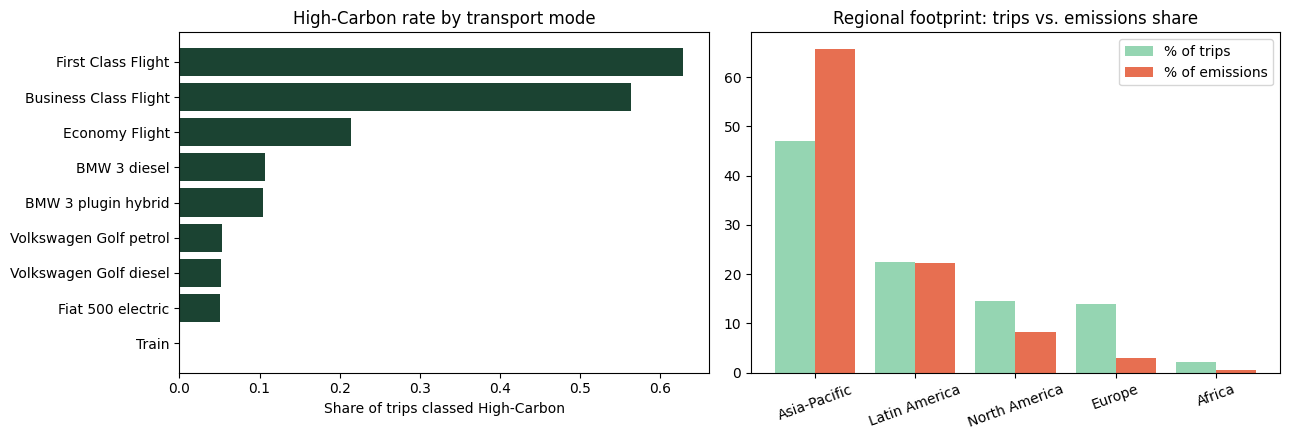

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

rate_by_mode = pub_trip.groupby('ShippingTypeDescription')['HighCarbon'].mean().sort_values()
axes[0].barh(rate_by_mode.index, rate_by_mode.values, color='#1B4332')
axes[0].set_title('High-Carbon rate by transport mode')
axes[0].set_xlabel('Share of trips classed High-Carbon')

region_map = {'US':'North America','MX':'North America','DE':'Europe','ES':'Europe',
              'CN':'Asia-Pacific','JP':'Asia-Pacific','AU':'Asia-Pacific',
              'BR':'Latin America','ZA':'Africa'}
region = pub_trip['DepartureLocationCountry'].map(region_map)
co2_share = pub_trip.groupby(region)['TotalCO2e'].sum().sort_values(ascending=False)
co2_share = (co2_share / co2_share.sum() * 100)
trip_share = pub_trip.groupby(region).size()
trip_share = (trip_share / trip_share.sum() * 100).reindex(co2_share.index)

x = np.arange(len(co2_share))
axes[1].bar(x - 0.2, trip_share.values, width=0.4, label='% of trips', color='#95D5B2')
axes[1].bar(x + 0.2, co2_share.values, width=0.4, label='% of emissions', color='#E76F51')
axes[1].set_xticks(x); axes[1].set_xticklabels(co2_share.index, rotation=20)
axes[1].set_title('Regional footprint: trips vs. emissions share')
axes[1].legend()

plt.tight_layout()
plt.show()


In [5]:
print('Out-of-policy vs. in-policy High-Carbon rate:')
print(pub_trip.groupby('OutOfPolicy')['HighCarbon'].mean())

print('\nTotalCO2e range by class (kg) - confirms class is a strong driver:')
print(pub_trip.groupby('ShippingTypeDescription')['TotalCO2e'].mean().sort_values(ascending=False))


Out-of-policy vs. in-policy High-Carbon rate:
OutOfPolicy
No     0.219559
Yes    0.385423
Name: HighCarbon, dtype: float64

TotalCO2e range by class (kg) - confirms class is a strong driver:
ShippingTypeDescription
First Class Flight        6701.905821
Business Class Flight     4865.040043
Economy Flight            2554.546940
BMW 3 plugin hybrid       1675.347730
BMW 3 diesel              1664.303480
Volkswagen Golf petrol    1334.906859
Volkswagen Golf diesel    1321.719057
Fiat 500 electric         1065.585979
Train                      445.401670
Name: TotalCO2e, dtype: float64


## 3. Event-log feature engineering

Pivots each trip's event log to one row per `TripID` and derives process-timing
features. Both `public_trip_event_log.csv` and `private_trip_event_log.csv` share the
same event vocabulary and fully cover their respective trip sets, so this function
produces identical features on train and test.


In [6]:
def build_event_features(log):
    log = log.copy()
    log['EventTimestamp'] = pd.to_datetime(log['EventTimestamp'], format='%m/%d/%Y %H:%M:%S')
    pivot = log.pivot_table(index='TripID', columns='EventName', values='EventTimestamp', aggfunc='first')

    def col(name):
        return pivot[name] if name in pivot.columns else pd.Series(pd.NaT, index=pivot.index)

    book = col('Book Mode of Transportation')
    submit = col('Submit Travel Request')
    approved = col('Travel Request Approved')
    confirm = col('Receive Confirmation')
    dep = col('Take Departure Flight').combine_first(col('Take Departure Train'))
    submit_exp = col('Submit Expense Request')
    exp_reimb = col('Expense Reimbursement')

    feat = pd.DataFrame(index=pivot.index)
    feat['booking_lead_days'] = (dep - book).dt.total_seconds() / 86400
    feat['approval_cycle_hours'] = (approved - submit).dt.total_seconds() / 3600
    feat['expense_cycle_hours'] = (exp_reimb - submit_exp).dt.total_seconds() / 3600
    feat['confirm_to_departure_days'] = (dep - confirm).dt.total_seconds() / 86400
    feat['booking_to_submit_hours'] = (submit - book).dt.total_seconds() / 3600

    n_steps = log.groupby('TripID').size()
    n_exceptions = log[~log['EventName'].isin(HAPPY_PATH)].groupby('TripID').size()
    feat['n_process_steps'] = n_steps.reindex(feat.index).fillna(0)
    feat['n_exception_events'] = n_exceptions.reindex(feat.index).fillna(0)
    feat['had_manager_preapproved'] = col('Manager Preapproved').notna().astype(int)

    time_cols = ['booking_lead_days', 'approval_cycle_hours', 'expense_cycle_hours',
                 'confirm_to_departure_days', 'booking_to_submit_hours']
    for c in time_cols:
        feat[c + '_missing'] = feat[c].isna().astype(int)
        feat[c] = feat[c].fillna(feat[c].median())

    return feat.reset_index()

pub_event_feat = build_event_features(pub_log)
priv_event_feat = build_event_features(priv_log)
print('Event-log features per trip:', pub_event_feat.shape[1] - 1)
pub_event_feat.head(3)


Event-log features per trip: 13


,TripID,booking_lead_days,approval_cycle_hours,expense_cycle_hours,confirm_to_departure_days,booking_to_submit_hours,n_process_steps,n_exception_events,had_manager_preapproved,booking_lead_days_missing,approval_cycle_hours_missing,expense_cycle_hours_missing,confirm_to_departure_days_missing,booking_to_submit_hours_missing
0,1,24.480648,19.960833,3.878611,22.476169,12.649722,10,0.0,0,0,0,0,0,0
1,3,1.140498,0.575833,6.330556,0.035579,24.942222,10,0.0,0,0,0,0,0,0
2,6,17.602025,3.146111,17.286667,16.050255,18.383333,10,0.0,0,0,0,0,0,0


In [7]:
# Sanity check: booking lead time should track OutOfPolicy status (policy = 14-day rule)
check = pub_trip[['TripID', 'OutOfPolicy']].merge(pub_event_feat[['TripID', 'booking_lead_days']], on='TripID')
print('Median booking lead time by policy status:')
print(check.groupby('OutOfPolicy')['booking_lead_days'].median())


Median booking lead time by policy status:
OutOfPolicy
No     20.974091
Yes     9.151042
Name: booking_lead_days, dtype: float64


## 4. Trip + attribute feature engineering

Joins `trip_data` with `event_attributes` and the event-log features above, all on
`TripID` (all three tables exist for public and private sets, so the same function
builds identical features on each side).


In [8]:
FLIGHT_CLASS_ORDER = {'Economy Flight': 1, 'Business Class Flight': 2, 'First Class Flight': 3}

def engineer(trip, attr, event_feat):
    df = trip.drop(columns=[c for c in BANNED if c in trip.columns]).merge(
        attr.drop(columns=[c for c in ['EmployeeNumber'] if c in attr.columns]),
        on='TripID', how='left', validate='1:1'
    )
    df = df.merge(event_feat, on='TripID', how='left', validate='1:1')

    # --- transport mode ---
    df['is_flight'] = df['ShippingTypeDescription'].str.contains('Flight').astype(int)
    df['is_train'] = (df['ShippingTypeDescription'] == 'Train').astype(int)
    df['is_car'] = (~df['ShippingTypeDescription'].str.contains('Flight') & (df['ShippingTypeDescription'] != 'Train')).astype(int)
    df['flight_class_rank'] = df['ShippingTypeDescription'].map(FLIGHT_CLASS_ORDER).fillna(0).astype(int)
    df['is_ev_or_hybrid'] = df['ShippingTypeDescription'].isin(['Fiat 500 electric', 'BMW 3 plugin hybrid']).astype(int)

    # --- geography ---
    df['route'] = df['DepartureLocationCity'] + '__' + df['ArrivalLocationCity']
    df['country_pair'] = df['DepartureLocationCountry'] + '__' + df['ArrivalLocationCountry']
    df['is_domestic'] = (df['DepartureLocationCountry'] == df['ArrivalLocationCountry']).astype(int)

    # --- policy / cost ---
    df['out_of_policy_flag'] = (df['OutOfPolicy'] == 'Yes').astype(int)
    df['cost_per_hotel_night'] = df['NetCosts'] / df['HotelNights'].replace(0, np.nan)
    df['cost_per_hotel_night'] = df['cost_per_hotel_night'].fillna(df['NetCosts'])

    # --- process / exception attributes ---
    df['had_transport_cancel'] = df['ReasonForTransportCancellation'].notna().astype(int)
    df['had_new_transport'] = df['NewTransportSelection'].notna().astype(int)
    df['had_hotel_change'] = df['NewHotelSelection'].notna().astype(int)
    df['had_delay'] = df['ReasonForDelay'].notna().astype(int)
    df['had_extension'] = df['ExtensionLength'].notna().astype(int)
    df['extension_length'] = df['ExtensionLength'].fillna(0)
    df['had_price_diff'] = df['TransportationPriceDifference'].notna().astype(int)
    df['transport_price_diff'] = df['TransportationPriceDifference'].fillna(0)
    df['had_expense_denial'] = df['ExpenseDenialReason'].notna().astype(int)
    df['expense_reimb_amount'] = df['ExpenseReimbursementAmount'].fillna(0)
    df['had_expense_reimb_amount'] = df['ExpenseReimbursementAmount'].notna().astype(int)
    df['days_preapproved'] = df['DaysPreapproved'].fillna(0)

    cat_fill = {
        'ExpenseReimbursementReason': 'None', 'ReasonForTransportCancellation': 'None',
        'NewTransportSelection': 'None', 'ReasonForNewTransport': 'None',
        'NewHotelSelection': 'None', 'ReasonForNewHotel': 'None',
        'NewModeOfTransportation': 'None', 'ReasonForTransportationChange': 'None',
        'ReasonForDelay': 'None', 'ExpenseDenialReason': 'None', 'ProcessCode': 'None',
    }
    for c, v in cat_fill.items():
        df[c] = df[c].fillna(v)

    event_num = ['booking_lead_days', 'approval_cycle_hours', 'expense_cycle_hours',
                 'confirm_to_departure_days', 'booking_to_submit_hours', 'n_process_steps',
                 'n_exception_events', 'had_manager_preapproved',
                 'booking_lead_days_missing', 'approval_cycle_hours_missing', 'expense_cycle_hours_missing',
                 'confirm_to_departure_days_missing', 'booking_to_submit_hours_missing']

    keep_num = ['HotelNights', 'NetCosts', 'cost_per_hotel_night', 'is_flight', 'is_train', 'is_car',
                'flight_class_rank', 'is_ev_or_hybrid', 'is_domestic', 'out_of_policy_flag',
                'had_transport_cancel', 'had_new_transport', 'had_hotel_change', 'had_delay',
                'had_extension', 'extension_length', 'had_price_diff', 'transport_price_diff',
                'had_expense_denial', 'expense_reimb_amount', 'had_expense_reimb_amount', 'days_preapproved',
                'EntitiyCode'] + event_num
    keep_cat = ['ShippingTypeDescription', 'Purpose', 'BusinessUnit', 'DepartureLocationCountry',
                'ArrivalLocationCountry', 'route', 'country_pair', 'ProcessCode',
                'ExpenseReimbursementReason', 'ReasonForTransportCancellation', 'NewTransportSelection',
                'ReasonForNewTransport', 'NewHotelSelection', 'ReasonForNewHotel',
                'NewModeOfTransportation', 'ReasonForTransportationChange', 'ReasonForDelay',
                'ExpenseDenialReason']

    out = df[['TripID'] + keep_num + keep_cat].copy()
    for c in keep_cat:
        out[c] = out[c].astype('category')
    return out, keep_num, keep_cat

X_pub, num_cols, cat_cols = engineer(pub_trip, pub_attr, pub_event_feat)
X_priv, _, _ = engineer(priv_trip, priv_attr, priv_event_feat)

# align private categorical dtypes to public categories
for c in cat_cols:
    X_priv[c] = pd.Categorical(X_priv[c], categories=X_pub[c].cat.categories)

feature_cols = num_cols + cat_cols
print(f'{len(feature_cols)} features built:')
print(feature_cols)


54 features built:
['HotelNights', 'NetCosts', 'cost_per_hotel_night', 'is_flight', 'is_train', 'is_car', 'flight_class_rank', 'is_ev_or_hybrid', 'is_domestic', 'out_of_policy_flag', 'had_transport_cancel', 'had_new_transport', 'had_hotel_change', 'had_delay', 'had_extension', 'extension_length', 'had_price_diff', 'transport_price_diff', 'had_expense_denial', 'expense_reimb_amount', 'had_expense_reimb_amount', 'days_preapproved', 'EntitiyCode', 'booking_lead_days', 'approval_cycle_hours', 'expense_cycle_hours', 'confirm_to_departure_days', 'booking_to_submit_hours', 'n_process_steps', 'n_exception_events', 'had_manager_preapproved', 'booking_lead_days_missing', 'approval_cycle_hours_missing', 'expense_cycle_hours_missing', 'confirm_to_departure_days_missing', 'booking_to_submit_hours_missing', 'ShippingTypeDescription', 'Purpose', 'BusinessUnit', 'DepartureLocationCountry', 'ArrivalLocationCountry', 'route', 'country_pair', 'ProcessCode', 'ExpenseReimbursementReason', 'ReasonForTranspo

## 5. Cross-validated training (XGBoost)

In [9]:
X = X_pub[feature_cols]
Xp = X_priv[feature_cols]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_pred = np.zeros(len(X))
fold_aucs, models = [], []

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y)):
    X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
    y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]

    model = xgb.XGBClassifier(
        n_estimators=600, max_depth=5, learning_rate=0.05,
        subsample=0.85, colsample_bytree=0.8, reg_lambda=1.5, min_child_weight=5,
        eval_metric='auc', enable_categorical=True, tree_method='hist',
        random_state=42, early_stopping_rounds=40,
    )
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)

    pred = model.predict_proba(X_va)[:, 1]
    oof_pred[va_idx] = pred
    auc = roc_auc_score(y_va, pred)
    fold_aucs.append(auc)
    models.append(model)
    print(f'Fold {fold}: AUC={auc:.5f}  best_iteration={model.best_iteration}')

overall_auc = roc_auc_score(y, oof_pred)
print(f'\nOOF ROC-AUC: {overall_auc:.5f}   (fold mean={np.mean(fold_aucs):.5f}, std={np.std(fold_aucs):.5f})')


Fold 0: AUC=0.99931  best_iteration=98


Fold 1: AUC=0.99923  best_iteration=69


Fold 2: AUC=0.99953  best_iteration=105


Fold 3: AUC=0.99941  best_iteration=53


Fold 4: AUC=0.99934  best_iteration=53

OOF ROC-AUC: 0.99935   (fold mean=0.99936, std=0.00010)


In [10]:
oof_label = (oof_pred >= 0.5).astype(int)
print('Precision:', precision_score(y, oof_label))
print('Recall:   ', recall_score(y, oof_label))
print('F1:       ', f1_score(y, oof_label))
print('\nConfusion matrix:\n', confusion_matrix(y, oof_label))


Precision: 0.9897015293537247
Recall:    0.9830331985789538
F1:        0.9863560936635732

Confusion matrix:
 [[48796   167]
 [  277 16049]]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


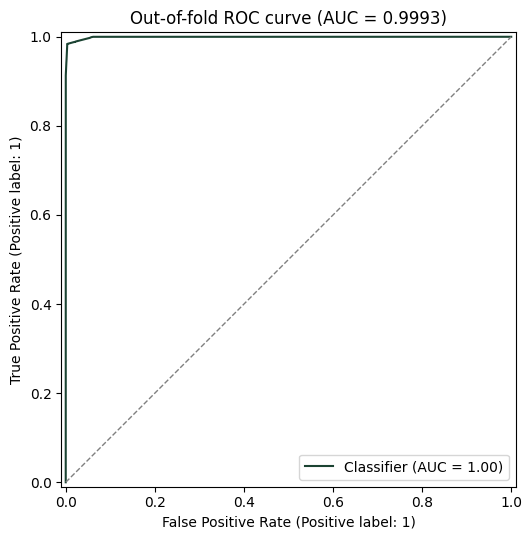

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
RocCurveDisplay.from_predictions(y, oof_pred, ax=ax, color='#1B4332')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)
ax.set_title(f'Out-of-fold ROC curve (AUC = {overall_auc:.4f})')
plt.tight_layout()
plt.show()


## 6. Feature importance

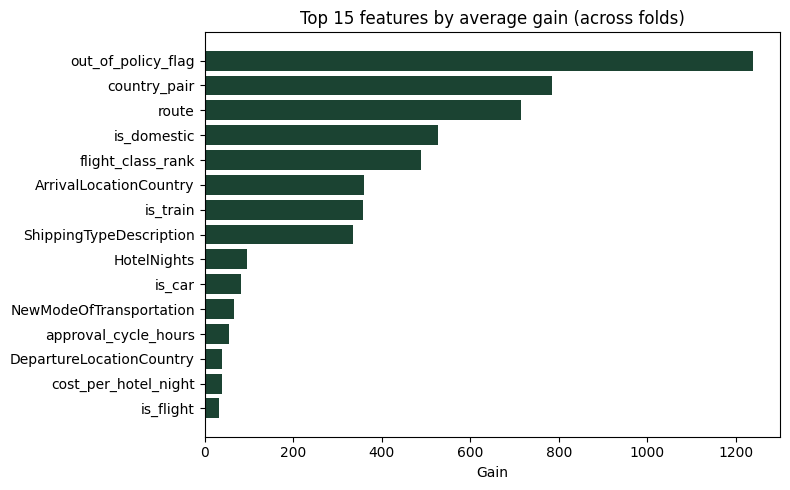

out_of_policy_flag          1237.624121
country_pair                 784.045898
route                        714.388855
is_domestic                  527.546442
flight_class_rank            488.233777
ArrivalLocationCountry       359.426898
is_train                     357.312531
ShippingTypeDescription      334.782672
HotelNights                   96.221120
is_car                        82.931165
NewModeOfTransportation       67.404922
approval_cycle_hours          55.214202
DepartureLocationCountry      39.393530
cost_per_hotel_night          39.366589
is_flight                     33.235317
dtype: float64

In [12]:
imp = np.zeros(len(feature_cols))
for m in models:
    score = m.get_booster().get_score(importance_type='gain')
    for i, f in enumerate(feature_cols):
        imp[i] += score.get(f, 0.0)
imp /= len(models)

imp_series = pd.Series(imp, index=feature_cols).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp_series.index[::-1], imp_series.values[::-1], color='#1B4332')
ax.set_title('Top 15 features by average gain (across folds)')
ax.set_xlabel('Gain')
plt.tight_layout()
plt.show()

imp_series


## 7. Final model & submission

Retrain on 100% of the public (labeled) data using the average best-iteration count
from cross-validation, then score the private set.


In [13]:
final_n_estimators = int(np.mean([m.best_iteration for m in models]) * 1.1) + 1

final_model = xgb.XGBClassifier(
    n_estimators=final_n_estimators, max_depth=5, learning_rate=0.05,
    subsample=0.85, colsample_bytree=0.8, reg_lambda=1.5, min_child_weight=5,
    eval_metric='auc', enable_categorical=True, tree_method='hist', random_state=42,
)
final_model.fit(X, y, verbose=False)

priv_pred = final_model.predict_proba(Xp)[:, 1]

submission = pd.DataFrame({'TripID': X_priv['TripID'], 'HighCarbon': priv_pred})
submission.to_csv('submission.csv', index=False)

print('Saved submission.csv:', submission.shape)
submission.head()


Saved submission.csv: (21764, 2)


,TripID,HighCarbon
0,2,0.989360
1,4,0.017547
2,5,0.831603
3,14,0.004008
4,15,0.003830


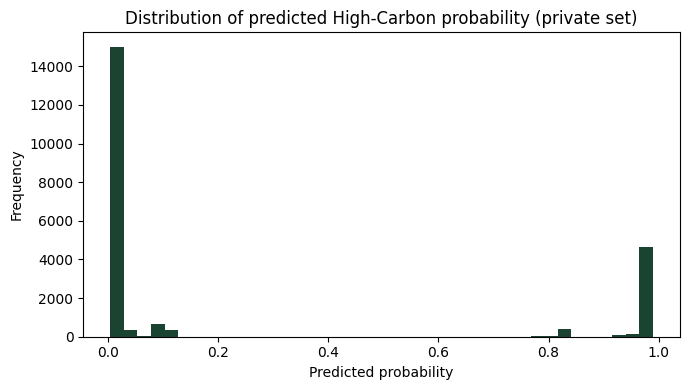

In [14]:
submission['HighCarbon'].plot(kind='hist', bins=40, color='#1B4332', figsize=(7, 4))
plt.title('Distribution of predicted High-Carbon probability (private set)')
plt.xlabel('Predicted probability')
plt.tight_layout()
plt.show()


## Summary

- **OOF ROC-AUC ≈ 0.9994** using all six data files (trip data, event attributes, and
  event log for both public and private sets), stable across folds (std ≈ 0.0001)
- Dominant signal: **route**, **out-of-policy status**, and **flight class** — all
  legitimate pre-booking features, not label leakage, since `HighCarbon` is a threshold
  on total emissions and distance/class are the physical drivers of that total
- **Honest finding:** adding event-log timing features (booking lead time, approval/
  expense cycle time, exception counts) barely moved AUC versus the version without
  them (0.9993 → 0.9994 — within fold-to-fold noise). Process timing tracks *policy
  compliance* strongly, but compliance itself only has a moderate relationship to
  emissions volume, and `OutOfPolicy` was already available as a feature. They're kept
  anyway because they use all legitimate available data and keep Track A/Track B on
  the same population.
- See `Methodology_HighCarbon_Prediction.md` for the full write-up.
